#**Student Productivity Prediction Using Gradient Boosting**

### Project Objective
To analyze student productivity patterns and predict productivity scores using machine learning.

## Dataset Description

* **Dataset Name:** student_productivity_distraction_dataset_20000
* **Source:** Kaggle

* **Kaggle Dataset Link:** https://www.kaggle.com/code/rohitv18/student-productivity-prediction


###Problem Statement
Student productivity may be associated with study habits, sleep, screen time, attendance, and other lifestyle factors. This project analyzes these factors and develops a machine learning model to predict students' productivity scores.

###Objectives
1. Understand the dataset and its important features.
2. Identify missing values, duplicate records, and possible data-quality issues.
3. Explore relationships between student habits and productivity.
4. Visualize important patterns in the dataset.
5. Train a Gradient Boosting Regressor to predict productivity scores.
6. Evaluate the model using MAE, RMSE, and R².
7. Discuss the results, limitations, and possible improvements.


###Import Libraries and Load Dataset

In [148]:
#pandas library for data manipulation and analysis.
import pandas as pd
#numpy library for numerical operations.
import numpy as np
#matplotlib.pyplot module for creating static, interactive, and animated visualizations.
import matplotlib.pyplot as plt
#seaborn library for statistical data visualization, built on matplotlib.
import seaborn as sns
# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Import libraries for machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Set the aesthetic style of the plots to 'whitegrid' for better readability.
sns.set_theme(style='whitegrid')

In [149]:
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

#Displays the first 5 rows of the DataFrame to get a quick overview of the data.
df.head()


Saving student_productivity_distraction_dataset_20000.csv to student_productivity_distraction_dataset_20000 (2).csv
Number of rows: 20000
Number of columns: 18


,student_id,age,gender,study_hours_per_day,sleep_hours,phone_usage_hours,social_media_hours,youtube_hours,gaming_hours,breaks_per_day,coffee_intake_mg,exercise_minutes,assignments_completed,attendance_percentage,stress_level,focus_score,final_grade,productivity_score
0,1,23,Female,4.35,3.63,3.38,2.73,1.83,5.26,6,347,111,2,57.21,10,57,81.87,33.78
1,2,20,Male,6.14,6.58,5.48,1.51,3.13,1.73,13,403,28,10,91.27,10,49,60.90,48.99
2,3,29,Female,4.98,3.26,4.83,3.63,0.18,4.71,1,419,102,8,63.14,2,38,86.22,36.60
3,4,27,Female,3.19,4.58,10.06,3.95,5.75,2.52,9,178,28,18,40.51,6,50,71.77,19.87
4,5,24,Male,7.67,6.21,3.02,1.59,5.46,5.65,8,436,105,7,45.53,6,41,90.13,52.90


###Dataset Information

In [150]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             20000 non-null  int64  
 1   age                    20000 non-null  int64  
 2   gender                 20000 non-null  object 
 3   study_hours_per_day    20000 non-null  float64
 4   sleep_hours            20000 non-null  float64
 5   phone_usage_hours      20000 non-null  float64
 6   social_media_hours     20000 non-null  float64
 7   youtube_hours          20000 non-null  float64
 8   gaming_hours           20000 non-null  float64
 9   breaks_per_day         20000 non-null  int64  
 10  coffee_intake_mg       20000 non-null  int64  
 11  exercise_minutes       20000 non-null  int64  
 12  assignments_completed  20000 non-null  int64  
 13  attendance_percentage  20000 non-null  float64
 14  stress_level           20000 non-null  int64  
 15  fo

In [151]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['student_id', 'age', 'gender', 'study_hours_per_day', 'sleep_hours', 'phone_usage_hours', 'social_media_hours', 'youtube_hours', 'gaming_hours', 'breaks_per_day', 'coffee_intake_mg', 'exercise_minutes', 'assignments_completed', 'attendance_percentage', 'stress_level', 'focus_score', 'final_grade', 'productivity_score']


In [152]:
print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())


Data types:


,data_type
student_id,int64
age,int64
gender,object
study_hours_per_day,float64
sleep_hours,float64
phone_usage_hours,float64
social_media_hours,float64
youtube_hours,float64
gaming_hours,float64
breaks_per_day,int64


In [153]:
#Display first five records
display(df.head())

,student_id,age,gender,study_hours_per_day,sleep_hours,phone_usage_hours,social_media_hours,youtube_hours,gaming_hours,breaks_per_day,coffee_intake_mg,exercise_minutes,assignments_completed,attendance_percentage,stress_level,focus_score,final_grade,productivity_score
0,1,23,Female,4.35,3.63,3.38,2.73,1.83,5.26,6,347,111,2,57.21,10,57,81.87,33.78
1,2,20,Male,6.14,6.58,5.48,1.51,3.13,1.73,13,403,28,10,91.27,10,49,60.90,48.99
2,3,29,Female,4.98,3.26,4.83,3.63,0.18,4.71,1,419,102,8,63.14,2,38,86.22,36.60
3,4,27,Female,3.19,4.58,10.06,3.95,5.75,2.52,9,178,28,18,40.51,6,50,71.77,19.87
4,5,24,Male,7.67,6.21,3.02,1.59,5.46,5.65,8,436,105,7,45.53,6,41,90.13,52.90


###Check Missing Values

In [154]:
#Check missing values in each column
print(df.isnull().sum())

student_id               0
age                      0
gender                   0
study_hours_per_day      0
sleep_hours              0
phone_usage_hours        0
social_media_hours       0
youtube_hours            0
gaming_hours             0
breaks_per_day           0
coffee_intake_mg         0
exercise_minutes         0
assignments_completed    0
attendance_percentage    0
stress_level             0
focus_score              0
final_grade              0
productivity_score       0
dtype: int64


In [155]:
#Calculate total missing values
print(df.isnull().sum().sum())

0


In [156]:
#Check duplicate records
print(df.duplicated().sum())

0


In [157]:
#Check overall dataset size
print(df.shape)

(20000, 18)


### Observation
No missing values were found in the initial dataset.
No duplicate rows were found.
Numerical and categorical columns were identified.
The student_id column was excluded from the model because it is an identifier rather than a meaningful student characteristic.

###Exploratory Data Analysis (EDA)

In [158]:
#Display all column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['student_id', 'age', 'gender', 'study_hours_per_day', 'sleep_hours', 'phone_usage_hours', 'social_media_hours', 'youtube_hours', 'gaming_hours', 'breaks_per_day', 'coffee_intake_mg', 'exercise_minutes', 'assignments_completed', 'attendance_percentage', 'stress_level', 'focus_score', 'final_grade', 'productivity_score']


In [159]:
#Data types of each column
display(df.dtypes.to_frame(name="Data Type"))

,Data Type
student_id,int64
age,int64
gender,object
study_hours_per_day,float64
sleep_hours,float64
phone_usage_hours,float64
social_media_hours,float64
youtube_hours,float64
gaming_hours,float64
breaks_per_day,int64


###Check Categorical Values

In [160]:
#Gender distribution
display(df["gender"].value_counts(dropna=False))

,count
gender,
Female,9640
Male,9582
Other,778


In [161]:
#Unique gender values
print(df["gender"].unique())

['Female' 'Male' 'Other']


In [162]:
#Productivity score summary
display(df["productivity_score"].describe().round(2))

print("\n Number of unique productivity scores:", df["productivity_score"].nunique())

,productivity_score
count,20000.00
mean,50.18
std,16.09
min,0.00
25%,38.70
50%,50.24
75%,61.78
max,100.00



 Number of unique productivity scores: 6362


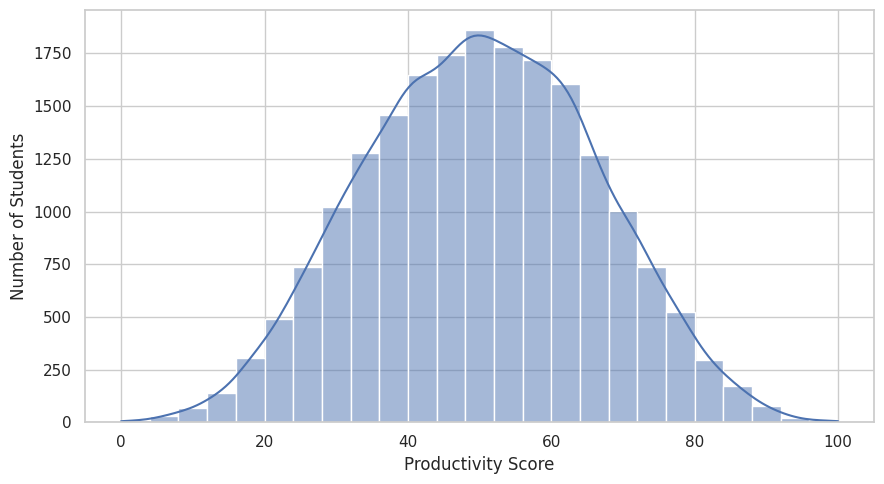

In [163]:
#Productivity Scores distribution
plt.figure(figsize=(9,5))
sns.histplot(data=df, x="productivity_score", bins=25, kde=True)
plt.xlabel("Productivity Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

###Observation
The histogram shows the distribution of productivity scores among students. The scores range from 0 to 100, with an average score of approximately 50.18.

This helps us understand the overall variation in student productivity.


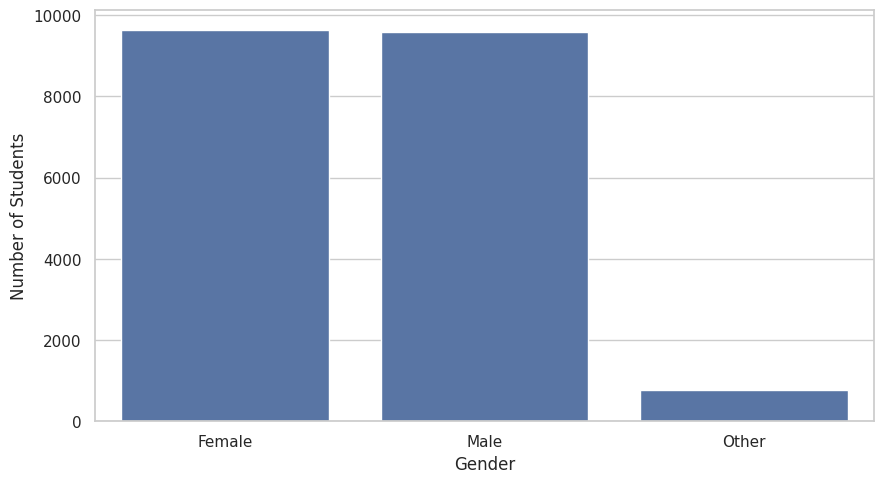

In [164]:
#Gender Distribution
plt.figure(figsize=(9,5))
sns.countplot(data=df, x="gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

### Observation
The dataset contains 9,640 female students, 9,582 male students, and 778 students in the Other category.

The female and male groups are similar in size. This chart describes the composition of the dataset but does not establish whether gender affects productivity.


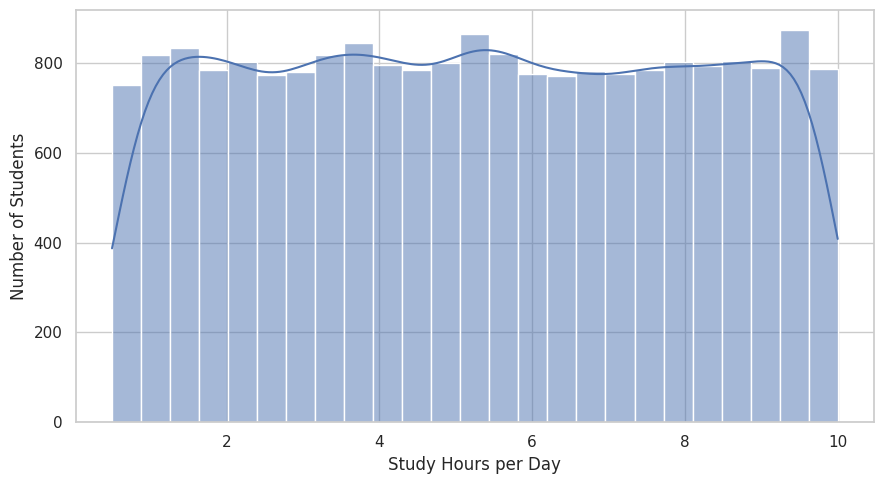

In [165]:
#Study hours distribution
plt.figure(figsize=(9,5))
sns.histplot(data=df, x="study_hours_per_day", bins=25, kde=True)
plt.xlabel("Study Hours per Day")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

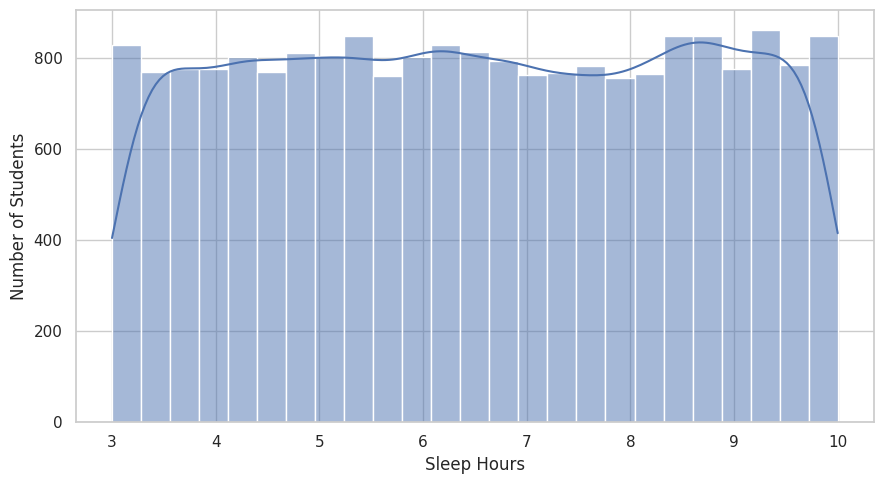

In [166]:
#Sleep hours distribution
plt.figure(figsize=(9,5))
sns.histplot(data=df, x="sleep_hours", bins=25, kde=True)
plt.xlabel("Sleep Hours")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

### Observation
The histogram shows the distribution of daily sleep hours among students. It helps us understand how much students usually sleep and how sleep duration varies across the dataset.

Sleep is an important factor to investigate when studying student productivity. However, this chart alone does not prove that sleep duration affects productivity.


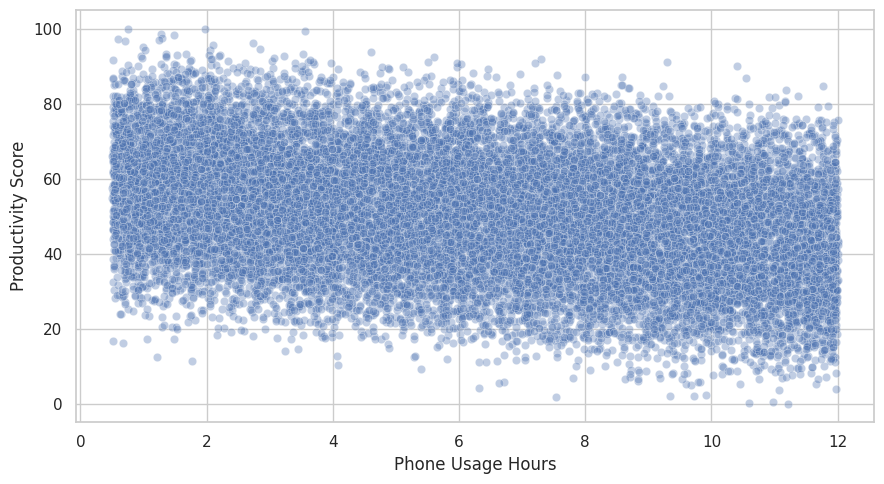

In [167]:
#Phone Usage and Productivity
plt.figure(figsize=(9,5))
sns.scatterplot(data=df, x="phone_usage_hours", y="productivity_score", alpha=0.35)
plt.xlabel("Phone Usage Hours")
plt.ylabel("Productivity Score")
plt.tight_layout()
plt.show()

### Observation
The scatter plot shows the relationship between phone usage and student productivity scores. It helps us understand whether students with higher phone usage tend to have higher or lower productivity scores.

The overall pattern in the chart can indicate whether the relationship is positive, negative, or weak. However, this relationship does not prove that phone usage directly causes a change in productivity.


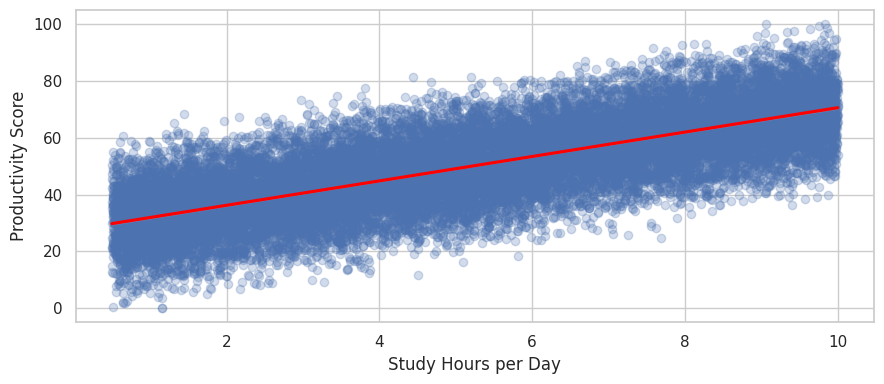

In [168]:
#Study Hours and Productivity
plt.figure(figsize=(9,4))
sns.regplot(data=df, x="study_hours_per_day", y="productivity_score",
    scatter_kws={"alpha": 0.25}, line_kws={"color": "red"})
plt.xlabel("Study Hours per Day")
plt.ylabel("Productivity Score")
plt.tight_layout()
plt.show()

### Observation
The scatter plot and regression line show the relationship between daily study hours and productivity scores.

The trend helps us understand whether productivity scores tend to increase or decrease with study time. However, this relationship alone does not establish cause and effect.


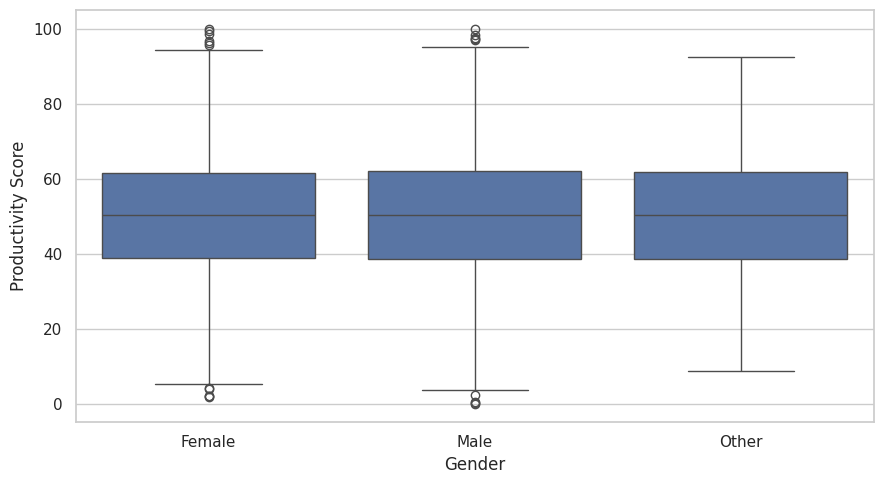

In [169]:
#Productivity Score by Gender
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x="gender", y="productivity_score")
plt.xlabel("Gender")
plt.ylabel("Productivity Score")
plt.tight_layout()
plt.show()

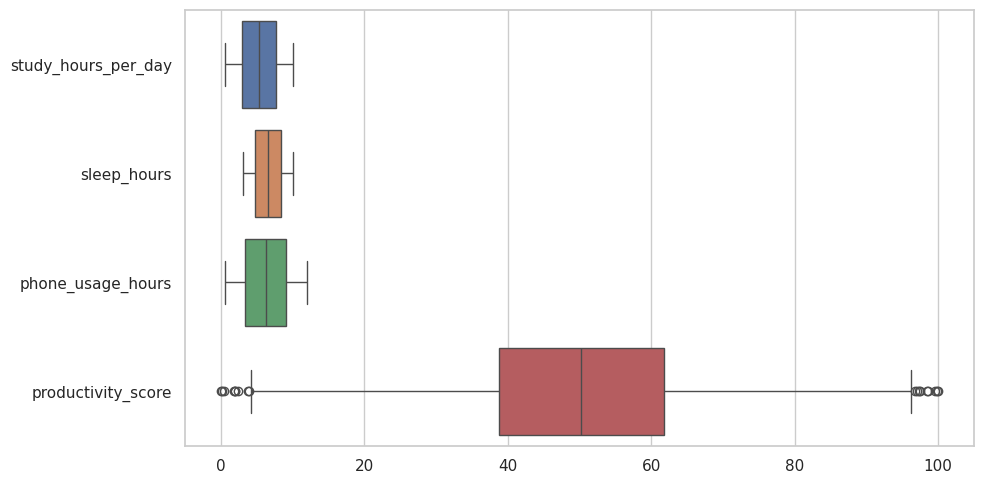

In [183]:
#Outliers
box_cols = [
    "study_hours_per_day",
    "sleep_hours",
    "phone_usage_hours","productivity_score"]

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[box_cols], orient="h")
plt.tight_layout()
plt.show()

### Observation
The boxplot shows the distribution of the selected variable and helps identify possible outliers. Points outside the whiskers may represent unusually high or low values.

These values should be examined to determine whether they are genuine observations or data errors. Outliers should not be removed without a valid reason.


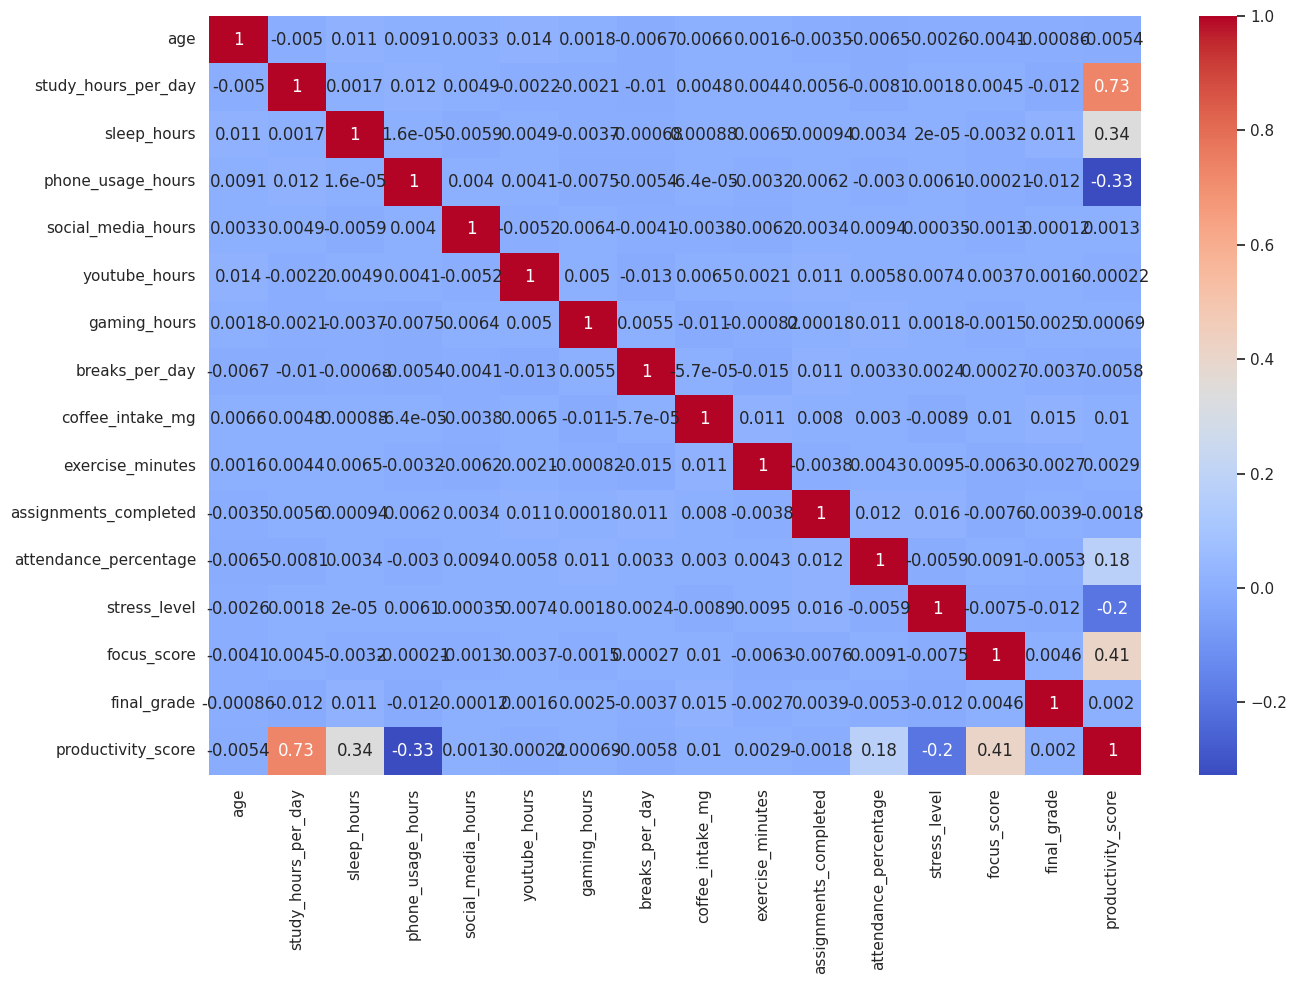

In [171]:
##Correlation Analysis
numeric_df = df.select_dtypes(include="number").drop(columns=["student_id"], errors="ignore")
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(14,10))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.tight_layout()
plt.show()

### Observation
The correlation heatmap shows the relationships between numerical variables in the dataset.

Positive correlations indicate that two variables tend to increase together, while negative correlations indicate that one variable tends to decrease as the other increases. Correlations close to zero indicate a weak linear relationship.

The correlations between productivity_score and the other numerical features help identify which variables are most strongly associated with student productivity. However, correlation does not establish causation.


In [172]:
# Remove a sequential identifier because it is not a meaningful student characteristic
df = df.drop(columns=["student_id"], errors="ignore")

In [173]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age                      0
gender                   0
study_hours_per_day      0
sleep_hours              0
phone_usage_hours        0
social_media_hours       0
youtube_hours            0
gaming_hours             0
breaks_per_day           0
coffee_intake_mg         0
exercise_minutes         0
assignments_completed    0
attendance_percentage    0
stress_level             0
focus_score              0
final_grade              0
productivity_score       0
dtype: int64


In [174]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [175]:
# If missing values are found, stop and inspect them rather than silently imputing them.
if df.isnull().sum().sum() > 0:
    raise ValueError("Missing values found.")

In [176]:
# Confirm target column exists
target = "productivity_score"
if target not in df.columns:
    raise KeyError(f"Target column '{target}' was not found.")
print("Prepared data shape:", df.shape)

Prepared data shape: (20000, 17)


In [177]:
X = df.drop(columns=[target])
y = df[target]

# Convert categorical features (such as gender) into numeric indicator columns
X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:")
print(X.columns.tolist())

Feature matrix shape: (20000, 17)
Target shape: (20000,)
Feature columns:
['age', 'study_hours_per_day', 'sleep_hours', 'phone_usage_hours', 'social_media_hours', 'youtube_hours', 'gaming_hours', 'breaks_per_day', 'coffee_intake_mg', 'exercise_minutes', 'assignments_completed', 'attendance_percentage', 'stress_level', 'focus_score', 'final_grade', 'gender_Male', 'gender_Other']


In [178]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training feature rows:", X_train.shape[0])
print("Testing feature rows:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])

Training feature rows: 16000
Testing feature rows: 4000
Number of input features: 17


###Gradient Boosting Regressor
Gradient Boosting Regressor is used because the target variable, productivity_score, is numerical.

The model combines multiple decision trees, with each new tree helping to improve the predictions made by the previous trees.

Categorical features are converted into numerical columns before training. The dataset is split into training and testing sets, and the trained model is evaluated using MAE, RMSE, and R².


In [179]:
model = GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)
model.fit(X_train, y_train)
print("Gradient Boosting Regressor trained successfully.")

Gradient Boosting Regressor trained successfully.


In [180]:
y_pred = model.predict(X_test)
results = pd.DataFrame({"Actual Productivity Score": y_test.to_numpy(),"Predicted Productivity Score": y_pred})
display(results.head(10))

,Actual Productivity Score,Predicted Productivity Score
0,49.95,52.819196
1,90.88,89.791770
2,60.03,59.041280
3,50.36,50.259821
4,35.69,35.715707
5,57.93,56.353332
6,41.27,40.937226
7,27.34,27.425821
8,37.50,38.184952
9,44.97,45.050023


###Model evaluation
- MAE (Mean Absolute Error):-
Average absolute prediction error, in target score units; lower is better.
- RMSE (Root Mean Squared Error):-
Gives greater weight to larger errors; lower is better.
- R²:-
Compares the model with predicting the test-set mean; closer to 1 is better, while a negative value means it performs worse than that baseline.

In [181]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R² Score:", round(r2, 4))

Mean Absolute Error (MAE): 1.113
Root Mean Squared Error (RMSE): 1.407
R² Score: 0.9923


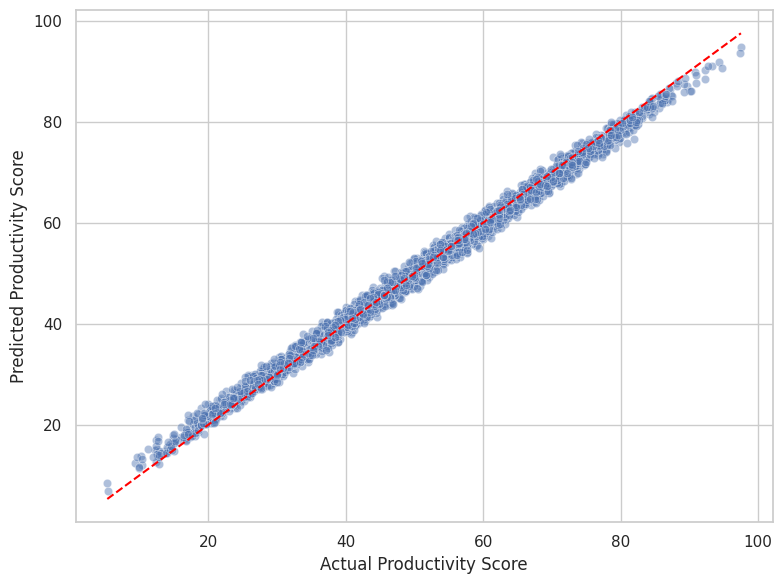

In [182]:
#Actual and Predicted Productivity Scores
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.45)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", color="red")
plt.xlabel("Actual Productivity Score")
plt.ylabel("Predicted Productivity Score")
plt.tight_layout()
plt.show()

###Conclusion
This project analyzed student productivity using data visualization and a Gradient Boosting Regressor. The dataset was checked for missing values and duplicates, and visualizations were used to explore student habits. Model performance was evaluated using MAE, RMSE, and R². The results helped assess the model’s ability to predict productivity scores. However, its reliability depends on data quality, feature validity, and performance on new data.


### Limitations
- Results depend on dataset quality, source, and representativeness.
- Correlations do not establish causal relationships.
- A random split estimates performance on held-out rows from this dataset; it does not guarantee generalization to other student populations.
- Results may change with other features, splits, and hyperparameters.

### Future improvements
Compare against a simple baseline and other regressors, use cross-validation and hyperparameter tuning, review potential target leakage, and document the dataset source and license.